# 04 · Two better recommenders (T6) and the first comparison table (T7)

**Steps T6 and T7 of the project plan.** Today's BOING suggests the same biggest groups to everyone (notebook 03).
Here we build two recommenders that look at *the user*:

- **"Also joined"** (T6a): people in the groups you are in also joined these groups.
- **Similar descriptions** (T6b): groups whose names and descriptions use the same words as your groups.

Then we score every method on the same quiz (T7): how often it finds the hidden groups, and who gets shown.
This table is the first version of experiment E1 for the report.

Run notebooks 01 and 02 first. The code shared by all notebooks is in `boingrec.py`, in this folder.

## 0 · Settings and data

In [1]:
# Colab only: upload sim_v1.zip and sim_v1_split.zip (from notebooks 01 and 02) and boingrec.py (from the notebooks folder),
# all three at once. Locally this cell does nothing.
import sys, zipfile
from pathlib import Path
if 'google.colab' in sys.modules and not Path('boingrec.py').exists():
    from google.colab import files
    for fname in files.upload():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(fname) as z:
                z.extractall('data')

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import boingrec as br

SEED, K = br.SEED, br.K      # 0 and 5, the same in every notebook
br.use_style()

vis = br.load_visible()      # what a recommender may read: no test file, no hidden column
ans = br.load_answers()      # the answer key: only the scoring code below reads it
tested = sorted(ans.test.user_id.unique())
name = vis.groups.set_index('group_id').name
print(f'{len(vis.train)} visible memberships, {len(ans.test)} hidden ones, {len(tested)} users to test, '
      f'{len(br.discover_groups(vis.groups))} groups on Discover')

6428 visible memberships, 1531 hidden ones, 1406 users to test, 129 groups on Discover


## 1 · A practice quiz for choosing settings

Some methods have a setting to choose. Choosing it by looking at the test scores would be peeking at the answers.
So we carve a **practice quiz** (a *validation set*) out of the training data, the same way notebook 02 made the test:
users with 3 or more training groups get 20% of them hidden (at least 1), and the posts and likes that would give them away are dropped.
Settings are chosen on the practice quiz; the test is used once, at the end.

In [3]:
fit, val = br.val_split(vis)     # fit: the training data minus the practice answers; val: the practice answers
val_users = sorted(val.user_id.unique())
print(f'Practice quiz: {len(val)} memberships hidden for {len(val_users)} users; {len(fit.train)} left to learn from '
      f'({len(vis.posts) - len(fit.posts)} posts and {len(vis.likes) - len(fit.likes)} likes dropped so they give nothing away)')

Practice quiz: 1093 memberships hidden for 1090 users; 5335 left to learn from (115 posts and 1336 likes dropped so they give nothing away)


## 2 · "Also joined" (T6a)

If many members of *Finals countdown* also joined *Midterms countdown*, we suggest Midterms countdown to the Finals members who are not in it yet.

1. A users × groups table of 0s and 1s (1 = member), from the training data.
2. For each pair of groups, the **overlap** (Jaccard) = members in both ÷ members in either: 0 = nobody in common, 1 = the same members.
3. A user's score for a group = the **sum** of its overlaps with each group the user is in. We keep the 5 best groups they can join.

The example below is checked by hand.

In [4]:
x = br.membership_matrix(vis)     # users x groups, 0/1
jac = br.jaccard_matrix(vis)      # groups x groups overlaps
a, b = 4, 23                      # Finals countdown and Midterms countdown, two of user 1's groups
both, either = int((x[a] & x[b]).sum()), int((x[a] | x[b]).sum())
print(f'{name[a]}: {x[a].sum()} members; {name[b]}: {x[b].sum()} members; {both} in both, {either} in either')
print(f'Overlap = {both} ÷ {either} = {both / either:.3f}   (boingrec: {jac.loc[a, b]:.3f})')
print(f'\nThe groups that overlap most with {name[a]}:')
print(jac.loc[a].nlargest(5).rename(name).round(3).to_string())

Finals countdown: 286 members; Midterms countdown: 221 members; 113 in both, 394 in either
Overlap = 113 ÷ 394 = 0.287   (boingrec: 0.287)

The groups that overlap most with Finals countdown:
group_id
Midterms countdown                     0.287
SAT prep squad                         0.241
MCAT countdown                         0.152
Entrance exams accountability group    0.089
Beat the IELTS                         0.073


## 3 · Similar descriptions (T6b)

This one reads the groups' **names and descriptions**, not who joined them, so it also works for a brand-new group nobody has joined yet.

1. **TF-IDF** (scikit-learn's `TfidfVectorizer`, default settings) turns each group's name + description into numbers. A word weighs more when it is
   rare across groups ("Korean") than when it is everywhere ("group", "the").
2. **Cosine similarity** says how alike two texts are: 1 = the same words, 0 = no word in common.
3. A user's score for a group = its **average** similarity to the user's groups.
4. The **topics a user chose to share** (`topics.csv`, for example *exam prep*) can count as one more "group" made of those words.
   How much they count (`topic_weight`) is a setting, chosen on the practice quiz in section 4.

In [5]:
sim = br.description_similarity(vis)
g = 47     # Entrance exams accountability group: user 1's hidden group
print(f'"{br.group_texts(vis)[g]}"  is most similar to:')
print(sim.loc[g].drop(g).nlargest(5).rename(name).round(3).to_string())

vectorizer, _ = br.tfidf_model(vis)
topic_words = sorted({w for t in vis.topics.topic.unique() for w in t.split('_')})
known = [w for w in topic_words if w in vectorizer.vocabulary_]
print(f'\n{vis.topics.user_id.nunique()} users shared topics. Topic words that appear in some group text: {", ".join(known)}.')
print(f'Never in any group text: {", ".join(w for w in topic_words if w not in known)}.')

"Entrance exams accountability group Tips, schedules and moral support."  is most similar to:
group_id
MCAT countdown              0.536
GRE prep squad              0.494
IELTS prep squad            0.494
SAT accountability group    0.232
AP exams countdown          0.225

676 users shared topics. Topic words that appear in some group text: art, exam, maths, music, physics, prep.
Never in any group text: careers, coding, fitness, habits, languages.


## 4 · Choosing the setting on the practice quiz

Popularity and "also joined" have nothing to tune. Similar descriptions has one setting: how much the shared topics count
(0 = not at all, 1 = like one more group). We try 0, 0.5, 1 and 2 on the practice quiz and keep the one with the best NDCG@5.
The other methods are scored on the practice quiz too, as a sanity check: it should rank them the same way as the test.

In [6]:
TOPIC_WEIGHTS = [0, 0.5, 1, 2]
val_rows = {br.label('random'): br.evaluate(br.random_lists(fit, val_users), val, fit, ans.group_topic),
            br.label('popularity'): br.evaluate(br.top_k(br.popularity_scores(fit, val_users), fit), val, fit, ans.group_topic),
            br.label('also_joined'): br.evaluate(br.top_k(br.also_joined_scores(fit, val_users), fit), val, fit, ans.group_topic)}
for w in TOPIC_WEIGHTS:
    lists_w = br.top_k(br.similar_descriptions_scores(fit, val_users, topic_weight=w), fit)
    val_rows[f'{br.label("descriptions")}, topic weight {w}'] = br.evaluate(lists_w, val, fit, ans.group_topic)
val_table = pd.DataFrame(val_rows).T
br.save_table(val_table, 't6_validation.csv')

ndcg_by_weight = [val_table.loc[f'{br.label("descriptions")}, topic weight {w}', 'ndcg@5'] for w in TOPIC_WEIGHTS]
TOPIC_WEIGHT = TOPIC_WEIGHTS[int(np.argmax(ndcg_by_weight))]       # the best on the practice quiz (ties: the smaller weight)
print(f'Chosen topic weight: {TOPIC_WEIGHT}')
val_table[['hit_rate', 'ndcg@5', 'newcomer_share', 'gini', 'coverage']].round(3)

Chosen topic weight: 0


,hit_rate,ndcg@5,newcomer_share,gini,coverage
Random (floor),0.044,0.025,0.440,0.089,129.0
Popularity (today),0.211,0.122,0.000,0.955,10.0
"""Also joined""",0.608,0.441,0.037,0.602,96.0
"Similar descriptions, topic weight 0",0.255,0.164,0.449,0.488,124.0
"Similar descriptions, topic weight 0.5",0.254,0.162,0.450,0.486,124.0
"Similar descriptions, topic weight 1",0.253,0.162,0.450,0.483,124.0
"Similar descriptions, topic weight 2",0.254,0.159,0.449,0.479,124.0


The shared topics do not help: their words rarely appear in group texts (*coding*, *languages* or *fitness* appear in none), and when they do
they are vague ("exam" is also in the language groups' "a trip or an exam in Korean"). So the best setting on the practice quiz ignores them.
They stay available (`topic_weight`) for members with no group yet (experiment E5), where they are the only clue we have.

## 5 · The first comparison table (T7, experiment E1 version 1)

Now the real quiz: each method suggests 5 groups to each of the 1,406 tested users, learning only from the training data,
and we score them against the hidden test memberships with the measures of T4 and T5.

| Column | Meaning |
|---|---|
| hit_rate | share of users with at least one right suggestion |
| precision@5, recall@5, ndcg@5 | as in notebook 03 |
| newcomer_share | share of all slots that go to new or small groups (R4) |
| gini | how unequal the slots are across the 129 groups on Discover (0 = equal) |
| coverage | how many different groups are ever shown |
| largest_share | share of all slots taken by the most-shown group (R4's cap) |
| topics_per_list | how many different topics a list of 5 covers (R5; uses the hidden topics, so only for scoring) |

In [7]:
ORDER = ['random', 'popularity', 'also_joined', 'descriptions']
test_lists = {
    'random': br.random_lists(vis, tested),
    'popularity': br.top_k(br.popularity_scores(vis, tested), vis),
    'also_joined': br.top_k(br.also_joined_scores(vis, tested), vis),
    'descriptions': br.top_k(br.similar_descriptions_scores(vis, tested, topic_weight=TOPIC_WEIGHT), vis),
}
e1 = pd.DataFrame({br.label(m): br.evaluate(test_lists[m], ans.test, vis, ans.group_topic) for m in ORDER}).T
e1[['users', 'coverage']] = e1[['users', 'coverage']].astype(int)
br.save_table(e1, 'e1_v1.csv')
e1.round(3)

,users,hit_rate,precision@5,recall@5,ndcg@5,newcomer_share,gini,coverage,largest_share,topics_per_list
Random (floor),1406,0.048,0.010,0.043,0.025,0.417,0.079,129,0.010,4.063
Popularity (today),1406,0.220,0.044,0.207,0.131,0.000,0.953,10,0.174,3.228
"""Also joined""",1406,0.640,0.136,0.621,0.499,0.027,0.599,94,0.031,2.037
Similar descriptions,1406,0.263,0.054,0.247,0.159,0.416,0.502,125,0.038,1.976


**How sure are we?** An average over 1,406 users still depends a little on which users happen to be tested. The ranges below (95%,
from resampling the users 2,000 times) show which differences are real. The random floor also moves with the seed: we redraw it 20 times.

In [8]:
per_user = {m: br.relevance_per_user(test_lists[m], ans.test) for m in ORDER}
ci_rows = {}
for m in ORDER:
    row = {}
    for metric in ['hit_rate', 'ndcg@5']:
        low, high = br.bootstrap_ci(per_user[m][metric])
        row.update({metric: per_user[m][metric].mean(), f'{metric} low': low, f'{metric} high': high})
    ci_rows[br.label(m)] = row
ci = pd.DataFrame(ci_rows).T
br.save_table(ci, 'e1_v1_ci.csv')

floor = pd.Series([br.evaluate(br.random_lists(vis, tested, seed=s), ans.test, vis)['hit_rate'] for s in range(20)])
print(f'Random floor over 20 seeds: hit rate {floor.mean():.3f} on average, from {floor.min():.3f} to {floor.max():.3f}')
ci.round(3)

Random floor over 20 seeds: hit rate 0.041 on average, from 0.032 to 0.054


,hit_rate,hit_rate low,hit_rate high,ndcg@5,ndcg@5 low,ndcg@5 high
Random (floor),0.048,0.038,0.060,0.025,0.019,0.033
Popularity (today),0.220,0.198,0.243,0.131,0.117,0.146
"""Also joined""",0.640,0.616,0.666,0.499,0.476,0.522
Similar descriptions,0.263,0.240,0.287,0.159,0.144,0.176


## 6 · The chart

Relevance (NDCG@5) and the newcomer share, side by side, with the same colour for each method as in every other figure.

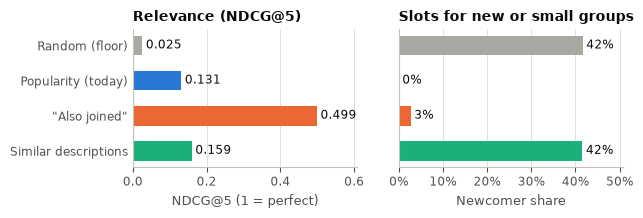

In [9]:
labels = [br.label(m) for m in ORDER]
y = np.arange(len(ORDER))[::-1]                       # first method at the top
panels = [('ndcg@5', 'Relevance (NDCG@5)', 'NDCG@5 (1 = perfect)', '{:.3f}'),
          ('newcomer_share', 'Slots for new or small groups', 'Newcomer share', '{:.0%}')]
fig, axes = plt.subplots(1, 2, figsize=(br.WIDTH, 2.25), sharey=True)
for ax, (col, title, xlabel, fmt) in zip(axes, panels):
    values = e1.loc[labels, col].to_numpy()
    ax.barh(y, values, height=0.56, color=[br.colour(m) for m in ORDER])
    for yi, v in zip(y, values):
        ax.text(v + values.max() * 0.02, yi, fmt.format(v), va='center', fontsize=8.5, color=br.INK)
    ax.set_xlim(0, values.max() * 1.22)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.xaxis.grid(True)
    ax.tick_params(axis='y', length=0)
axes[0].set_yticks(y, labels)
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
fig.tight_layout(w_pad=2)
br.save_fig(fig, 't7_comparison.png')
plt.show()

## 7 · An example: user 1

User 1 again (the example of T3 and T4): every method sees the same four groups and must guess the hidden one.

In [10]:
br.print_example(1, {m: test_lists[m] for m in ['popularity', 'also_joined', 'descriptions']}, vis, ans.test)

User 1 is in: Finals countdown, Journaling streak, Korean conversation club, Midterms countdown
Hidden (the answer): Entrance exams accountability group

Popularity (today):
  1. Weightlifting for beginners (295 members) 
  2. Japanese in 90 days (220 members) 
  3. Algorithms study group (219 members) 
  4. Spanish for beginners (206 members) 
  5. Algorithms from zero (200 members) 

"Also joined":
  1. SAT prep squad (151 members) 
  2. Spanish for beginners (206 members) 
  3. Japanese in 90 days (220 members) 
  4. MCAT countdown (86 members) 
  5. 30 days of Reading (91 members) 

Similar descriptions:
  1. Better Journaling (39 members) 
  2. Beat the Finals (26 members) 
  3. Spanish for beginners (206 members) 
  4. Arabic in 90 days (48 members) 
  5. Japanese in 90 days (220 members) 


No method finds *Entrance exams accountability group* in its top 5 here, but the lists are no longer the same for everyone:
"also joined" offers two other exam groups (*SAT prep squad*, *MCAT countdown*), because members of Finals countdown and Midterms countdown often joined them.
Similar descriptions follows words: *Better Journaling* matches Journaling streak, *Beat the Finals* matches Finals countdown, and three language groups
share Korean conversation club's description ("Getting ready for a trip or an exam in ...? Practise here.").

## 8 · Checks

In [11]:
from sklearn.metrics import ndcg_score

gids = br.group_ids(vis)
hidden = ans.test.groupby('user_id').group_id.apply(set)
t4 = pd.read_csv(br.RESULTS / 't4_baseline.csv', index_col=0)
allowed = br.candidate_mask(vis, tested)

def ndcg_sklearn(suggested, hidden_set):
    # scikit-learn's NDCG@5: true relevance 1 for the hidden groups; scores 5, 4, ..., 1 for the 5 suggestions, 0 elsewhere
    y_true = np.isin(gids, list(hidden_set)).astype(float)
    y_score = np.zeros(len(gids))
    y_score[np.searchsorted(gids, suggested)] = np.arange(len(suggested), 0, -1)
    return ndcg_score([y_true], [y_score], k=K)

with_hit = [u for u in tested if hidden[u] & set(test_lists['also_joined'][u])]
some = with_hit[:20] + tested[:20]
full = pd.concat([vis.train, ans.test]).sort_values(['user_id', 'group_id']).reset_index(drop=True)
again_train, again_test = br.split_memberships(full, vis.users, vis.groups)
pairs = lambda df: set(zip(df.user_id, df.group_id))
like_pairs = set(zip(fit.likes.user_id, fit.likes.post_id.map(fit.posts.set_index('post_id').group_id)))
again = {'random': br.random_lists(vis, tested),
         'also_joined': br.top_k(br.also_joined_scores(vis, tested), vis),
         'descriptions': br.top_k(br.similar_descriptions_scores(vis, tested, topic_weight=TOPIC_WEIGHT), vis)}
toy = br.popularity_scores(vis, [1]) * 0            # every score equal

checks = {
    'every tested user gets exactly 5 different groups from every method':
        all(len(set(lists[u])) == K == len(lists[u]) for lists in test_lists.values() for u in tested),
    'every suggestion is allowed: on Discover, not joined, not marked "not interested"':
        all(allowed.loc[u, g] for lists in test_lists.values() for u in tested for g in lists[u]),
    'our NDCG@5 equals scikit-learn\'s ndcg_score (40 users, every method)':
        all(abs(br.relevance(lists[u], hidden[u])['ndcg@5'] - ndcg_sklearn(lists[u], hidden[u])) < 1e-12
            for lists in test_lists.values() for u in some),
    'popularity gives exactly the T4 scores': (e1.loc['Popularity (today)', br.RELEVANCE].round(3) == t4.loc['Popularity (today)', br.RELEVANCE]).all(),
    'the overlap example matches the hand count': abs(jac.loc[a, b] - both / either) < 1e-12,
    'equal scores: the smaller group id comes first': br.top_k(toy, vis)[1] == br.candidates(vis, 1)[:K],
    'a recommender never gets a hidden column or a test membership':
        not {'interests', 'is_fake'} & set(vis.users.columns) and 'topic' not in vis.groups.columns
        and not pairs(vis.train) & pairs(ans.test),
    'boingrec\'s split rebuilds notebook 02\'s test set exactly': again_test.equals(ans.test) and again_train.equals(vis.train),
    'practice quiz: its answers come from the training data, and are not visible any more':
        pairs(val) <= pairs(vis.train) and not pairs(val) & pairs(fit.train) and len(fit.train) + len(val) == len(vis.train),
    'practice quiz: no post or like gives a practice answer away':
        not pairs(fit.posts[fit.posts.group_id > 0]) & pairs(val) and not like_pairs & pairs(val),
    'the practice quiz ranks the methods like the test (by NDCG@5)':
        list(val_table.loc[[br.label(m) for m in ORDER[:3]] + [f'{br.label("descriptions")}, topic weight {TOPIC_WEIGHT}'], 'ndcg@5'].rank())
        == list(e1['ndcg@5'].rank()),
    'same seed, same results: running the methods again gives the same lists': all(again[m] == test_lists[m] for m in again),
}
for check, ok in checks.items():
    print('✓' if ok else '✗', check)
assert all(checks.values()), 'Some checks failed (see ✗ above)'

✓ every tested user gets exactly 5 different groups from every method
✓ every suggestion is allowed: on Discover, not joined, not marked "not interested"
✓ our NDCG@5 equals scikit-learn's ndcg_score (40 users, every method)
✓ popularity gives exactly the T4 scores
✓ the overlap example matches the hand count
✓ equal scores: the smaller group id comes first
✓ a recommender never gets a hidden column or a test membership
✓ boingrec's split rebuilds notebook 02's test set exactly
✓ practice quiz: its answers come from the training data, and are not visible any more
✓ practice quiz: no post or like gives a practice answer away
✓ the practice quiz ranks the methods like the test (by NDCG@5)
✓ same seed, same results: running the methods again gives the same lists


## What we learned

- **"Also joined" is by far the most relevant.** It finds a hidden group for **64%** of users (popularity 22%, random 5%), with NDCG@5 = **0.499**
  against 0.131 for popularity (95% ranges 0.476–0.522 and 0.117–0.146). But it shows newcomers little: **2.7%** of slots go to new or small groups,
  the Gini of exposure is 0.599, and 94 of the 129 groups are ever shown.
- **Similar descriptions is the fairest, but only a little more relevant than popularity:** NDCG@5 = **0.159** (hit rate 26%), with **41.6%** of slots
  for new or small groups (as many as random suggestions), a Gini of 0.502 and 125 groups shown. It can suggest a group nobody has joined yet.
- **Both personal methods narrow the lists** to about 2 topics in 5 suggestions (popularity 3.2, random 4.1). Rule R5 (at most *n* per topic) is there for this.
- The topics members shared did not help on the practice quiz (topic weight 0 was chosen): their words rarely appear in group texts.
- **A caution for the report:** the hidden answers come from a simulator in which bigger groups attract more joins, so only 2.7% of the hidden memberships
  are in new or small groups. A quiz like this rewards favouring big groups, so it understates what showing newcomers is worth.
- **The tension for E2:** the most relevant method is also the one that shows newcomers least. Next: the hidden-tastes model (T9), a hybrid,
  and a re-ranker that reserves *q*% of the slots for new or small groups.
- Files: `results/e1_v1.csv` (the table), `results/e1_v1_ci.csv` (the 95% ranges), `results/t6_validation.csv` (the practice quiz), `figures/t7_comparison.png`.